# FD · Що саме згоріло у 2023 році і скільки?

**Тип:** виміряно. **Навіщо:** Площа й межі згарища потрібні для оцінки збитків і відновлення, а польове обстеження великої пожежі триває місяцями.

Цей ноутбук повторює блок сторінки досліджень `web/science/#a` і бере ті самі результати.

In [1]:
import sys
sys.path.insert(0, '..')
import pandas as pd
from eaglewings.ds import report
pd.set_option('display.width', 200)
%matplotlib inline

## Постановка, дані, протокол і метрики

Текст узято з модуля задачі, той самий записується в журнал кожного запуску.

In [2]:
print(report.protocol('FD'))

T1 · Картування згарища пожежі 2023.

Задача      бінарна сегментація: піксель лісу (30 м) у парку втрачено пожежею 2023 р.?
Лейбли      Hansen GFC lossyear ∈ {2023, 2024} (Landsat; незалежні від FIRMS і MODIS сенсор та алгоритм).
            2024 включено, бо частина дерев гине із запізненням; варіант лише 2023 — як перевірка стійкості до визначення лейбла.
            Обмеження: низова пожежа без загибелі крон = 0 у Hansen → precision будь-якого «вогневого» підходу занижена.
Домен       ліс 2000 р. (treecover ≥ 30 %) у межах парку і сітки H3.
Протокол    просторовий спліт за блоками H3 res 7 (~5 км²) у кожному парку: 50 % блоків — калібрування (вибір порогів / гіперпараметрів),
            50 % — тест. Парків кілька (ds/regions.py): налаштування й переможця обираємо на калібрувальних блоках усіх парків разом,
            тест рахуємо для всіх разом і окремо для кожного парку (колонки *_<парк>), з CI по блоках цього парку.
Метрики     F1 (= Dice) — основна: баланс commission/omission,

## Результат

Обраний підхід виділено. Вибір робився лише на валідації, числа тут з тесту.

,family,calib_f1,test_f1,test_f1_ci,test_f1_effis,champion,diff_base,diff_lo,diff_hi
0,s2_dnbr,0.882,0.872,0.809–0.914,0.813,True,0.21,0.153,0.271
1,modis_rdndvi,0.815,0.797,0.724–0.851,0.848,False,NaN,NaN,NaN
2,modis_dndvi,0.805,0.790,0.718–0.841,0.869,False,NaN,NaN,NaN
3,hybrid,0.803,0.787,0.715–0.835,0.866,False,NaN,NaN,NaN
4,firms_hull,0.763,0.746,0.673–0.805,0.949,False,NaN,NaN,NaN
5,firms_st_dbscan,0.659,0.665,0.592–0.725,0.905,False,NaN,NaN,NaN
6,firms_pixels,0.654,0.662,0.589–0.723,0.902,False,NaN,NaN,NaN


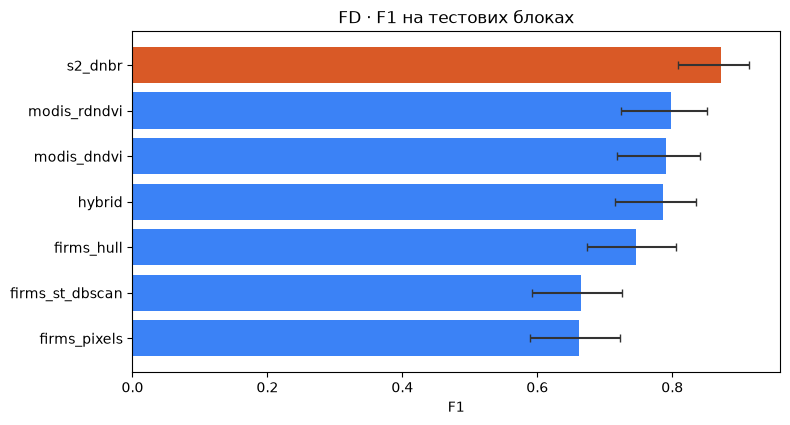

In [3]:
table, fig = report.show('FD')
table